# Superstore: What Drives Profit, and When Do Discounts Cause Losses?

**Business question:** a retail company sells office supplies, furniture and technology products. About one in five order lines loses money. I want to find out:

1. Which factors explain the profit of an order line?
2. At what discount level do orders stop being profitable?
3. Are some product groups or regions unprofitable because of the products themselves, or because of the discounts they get?

**Data:** the *Sample – Superstore* dataset, a fictional retail dataset published by Tableau. Each row is one product line in an order (10,194 rows, orders from 2023 to 2026).

**Approach:** exploratory analysis first, then linear regression (OLS) with `statsmodels` to measure the effect of each factor, cross-validation to compare models, and residual diagnostics to check the final model.

## 1. Load and check the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.formula.api as smf

BLUE, ORANGE = "#2a78d6", "#eb6834"   # blue = profit / main series, orange = loss
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("data/superstore.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     10194 non-null  str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("Rows with Sales <= 0:", (df["Sales"] <= 0).sum())
print()
print(df["Country/Region"].value_counts())

Missing values: 0
Duplicated rows: 0
Rows with Sales <= 0: 0

Country/Region
United States    9994
Canada            200
Name: count, dtype: int64


There are no missing values, no duplicated rows and no zero or negative sales.

`Country/Region` has two values: almost all rows are from the United States, 200 rows are from Canada. The Canadian provinces are already assigned to the regions `East` and `West`, so the column `Region` covers the location and I don't need `Country/Region` in the model.

In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Year"] = df["Order Date"].dt.year

yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly.round(2)

,Sales,Profit,Margin
Year,,,
2023,494040.21,51684.30,0.10
2024,472993.03,62020.97,0.13
2025,613933.58,82665.20,0.13
2026,745567.53,95926.35,0.13


Sales and profit grow every year, and the overall profit margin stays between about 10% and 13%. The yearly numbers look stable, so I analyse all four years together.

## 2. Select columns

I remove columns that are identifiers, that have too many categories for a simple model, or that are covered by another column. I also rename the columns to `snake_case`, so that they can be used directly in `statsmodels` formulas.

In [4]:
cols_to_drop = ["Row ID", "Order ID", "Customer ID", "Customer Name",   # identifiers
                "Product ID", "Product Name", "Postal Code",
                "Country/Region",            # covered by Region
                "Order Date", "Ship Date",   # time is not part of this analysis
                "City", "State/Province"]    # too many categories

df = df.drop(columns=cols_to_drop)
df.columns = (df.columns.str.lower()
              .str.replace(" ", "_").str.replace("-", "_"))
df.head()

,ship_mode,segment,region,category,sub_category,sales,quantity,discount,profit,year
0,Standard Class,Consumer,Central,Office Supplies,Paper,16.448,2,0.2,5.5512,2023
1,Standard Class,Home Office,Central,Office Supplies,Binders,3.540,2,0.8,-5.4870,2023
2,Standard Class,Home Office,Central,Office Supplies,Labels,11.784,3,0.2,4.2717,2023
3,Standard Class,Home Office,Central,Office Supplies,Storage,272.736,3,0.2,-64.7748,2023
4,Standard Class,Consumer,East,Office Supplies,Art,19.536,3,0.2,4.8840,2023


## 3. The target: profit

count    10194.00
mean        28.67
std        232.47
min      -6599.98
25%          1.76
50%          8.69
75%         29.30
max       8399.98
Name: profit, dtype: float64


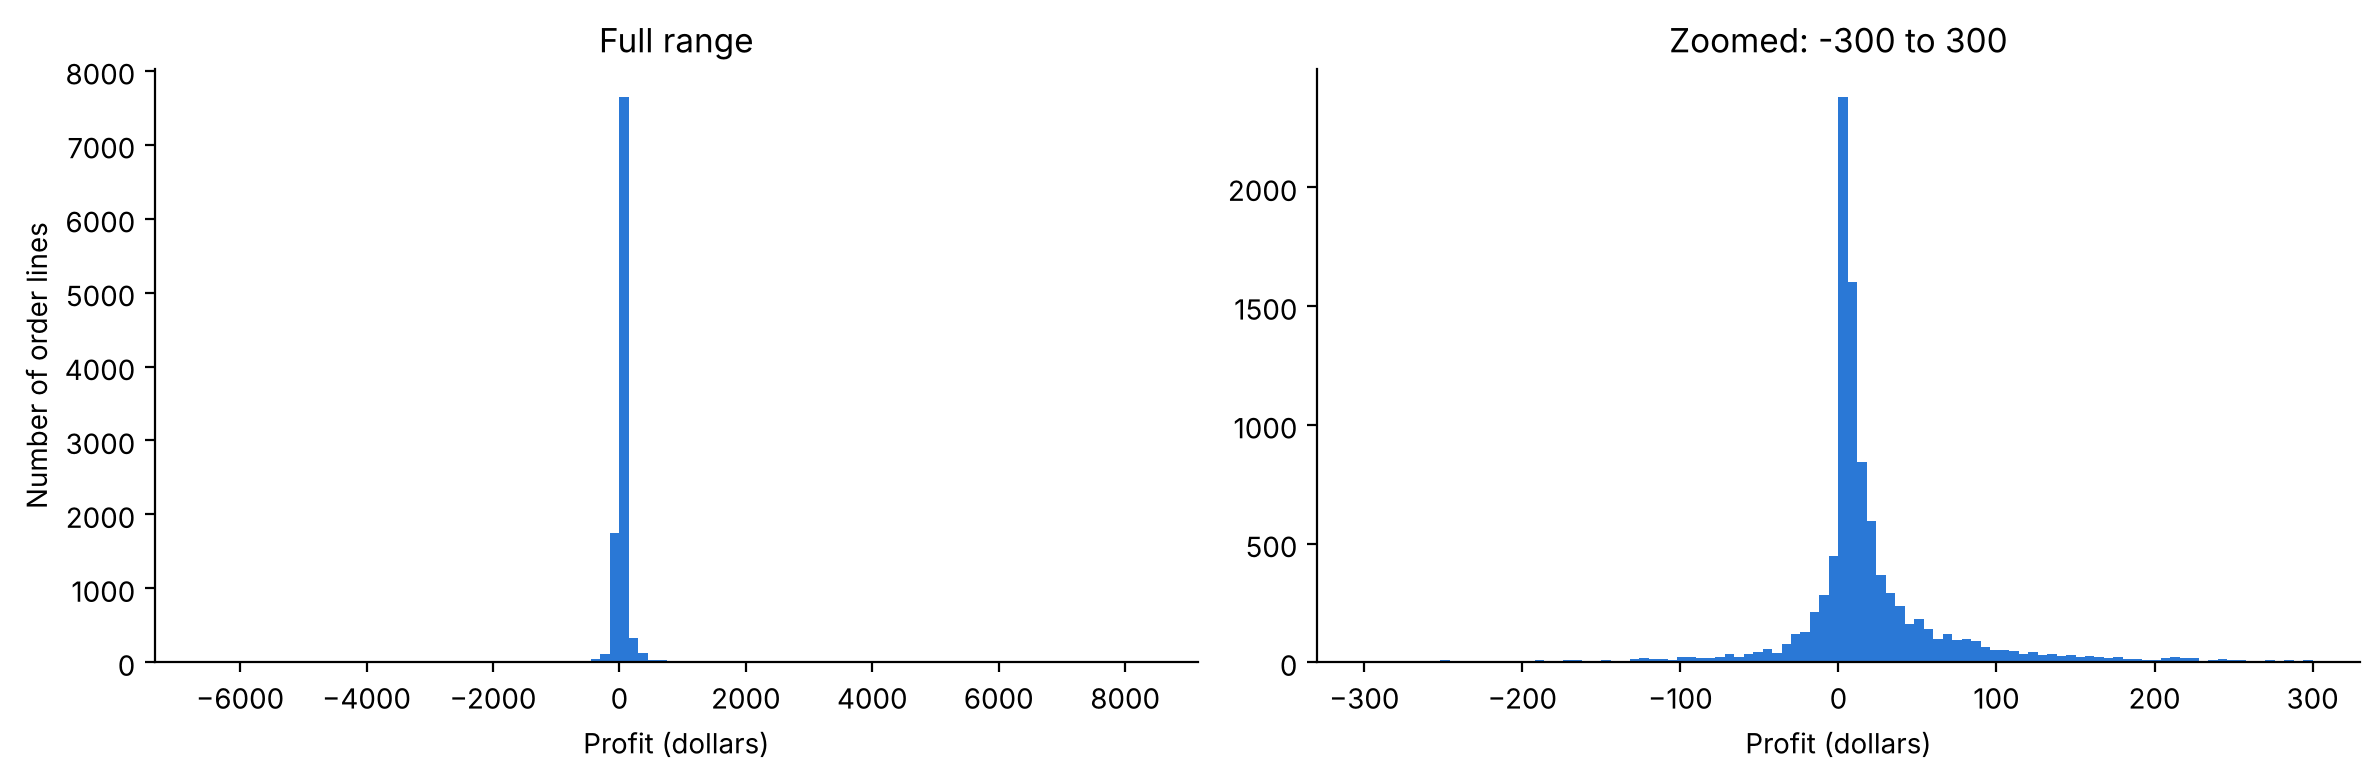

Share of order lines with a loss: 18.6%


In [5]:
print(df["profit"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["profit"].hist(bins=100, ax=axes[0], color=BLUE, grid=False)
axes[0].set_xlabel("Profit (dollars)")
axes[0].set_ylabel("Number of order lines")
axes[0].set_title("Full range")

# zoom into the main part of the data
df["profit"].hist(bins=100, range=(-300, 300), ax=axes[1], color=BLUE, grid=False)
axes[1].set_xlabel("Profit (dollars)")
axes[1].set_title("Zoomed: -300 to 300")

plt.tight_layout()
plt.show()

print(f"Share of order lines with a loss: {(df['profit'] < 0).mean():.1%}")

Profit is very unevenly distributed: half of the order lines earn less than 9 dollars, but a few lines earn or lose several thousand dollars. The standard deviation (about 232) is much larger than the mean (about 29). About 19% of the order lines lose money.

Because profit depends so strongly on the size of the order, I also calculate the **profit margin** (profit as a share of sales). It makes small and large orders comparable.

In [6]:
df["margin"] = df["profit"] / df["sales"]
df["margin"].describe().round(3)

count    10194.000
mean         0.122
std          0.465
min         -2.750
25%          0.075
50%          0.270
75%          0.362
max          0.500
Name: margin, dtype: float64

## 4. Explore the relationships

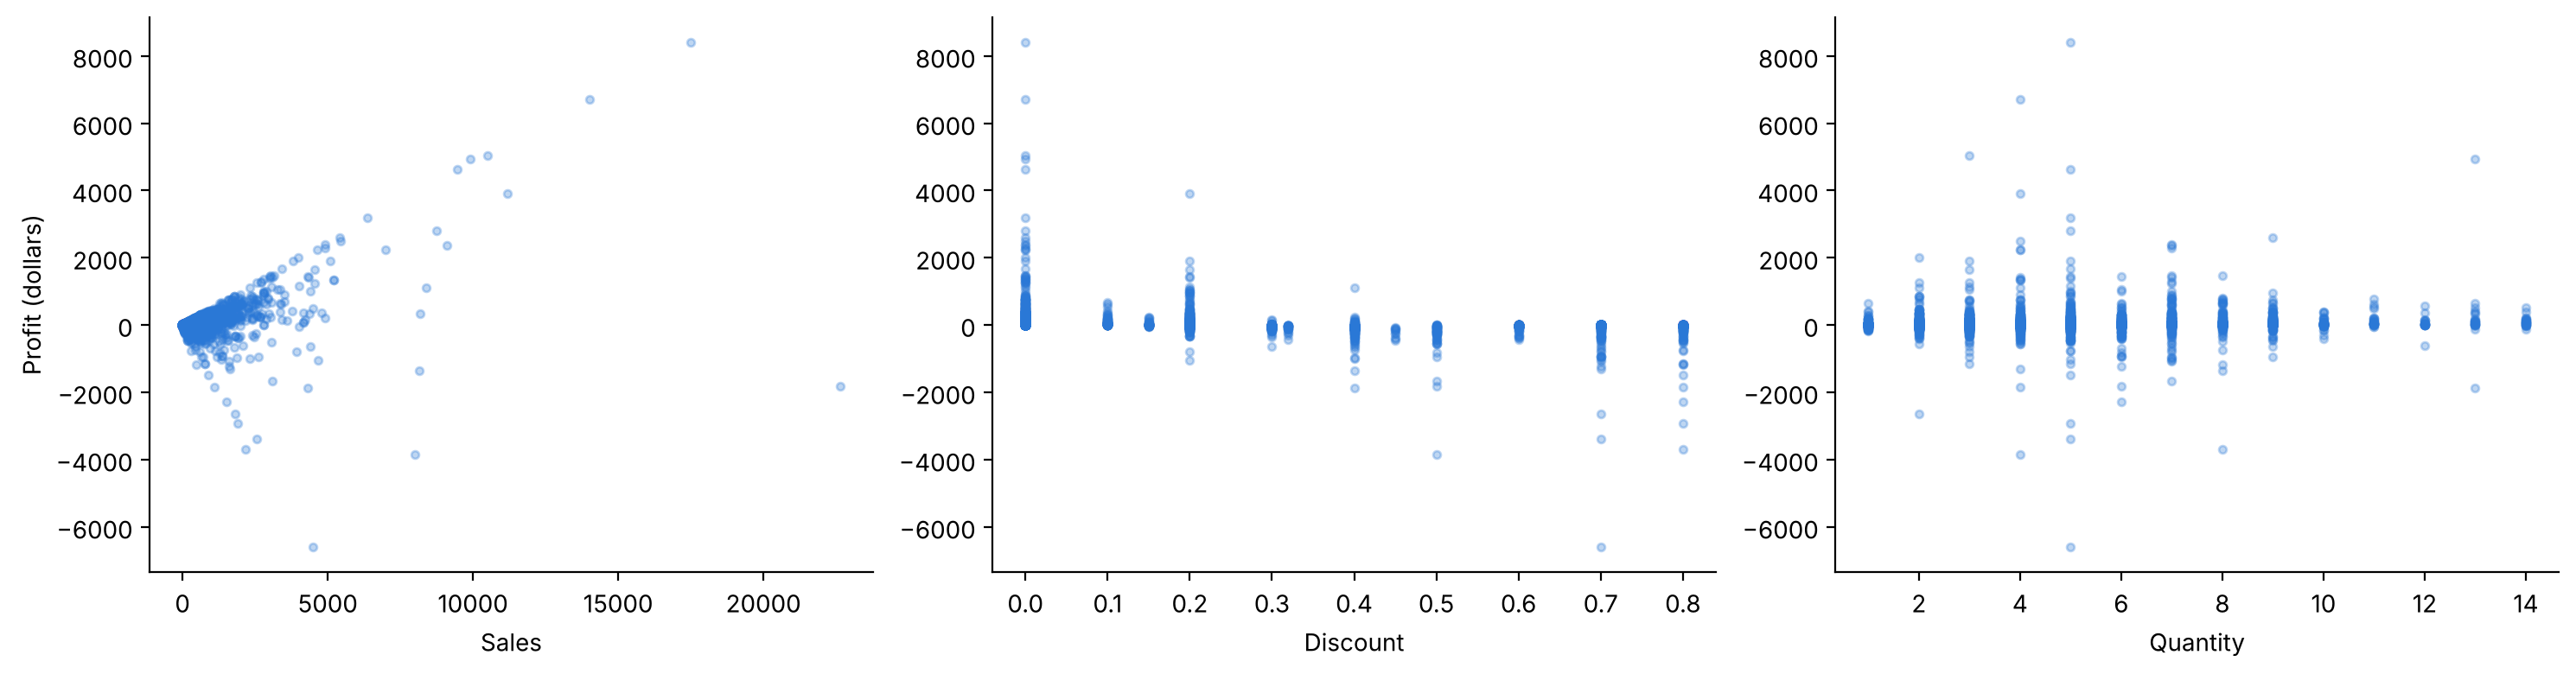

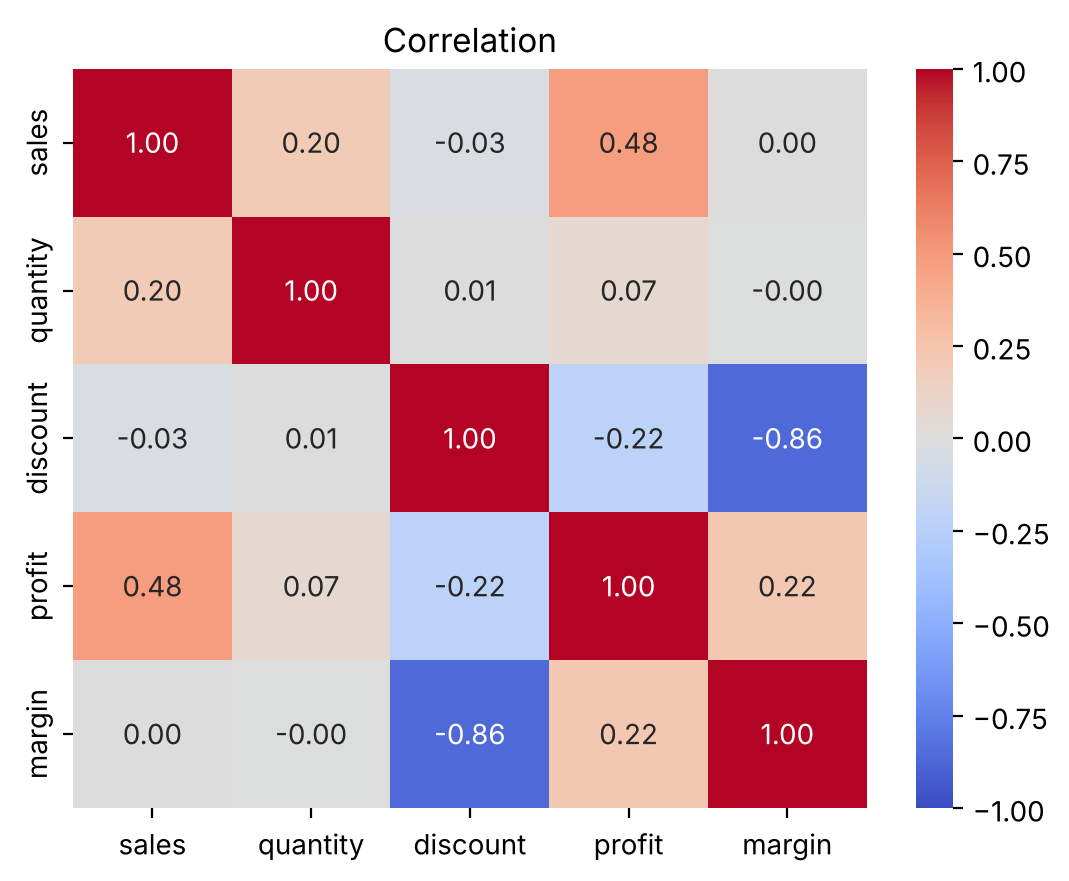

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["sales", "discount", "quantity"]):
    ax.scatter(df[col], df["profit"], alpha=0.3, s=10, color=BLUE)
    ax.set_xlabel(col.capitalize())
axes[0].set_ylabel("Profit (dollars)")

plt.tight_layout()
plt.show()

corr = df[["sales", "quantity", "discount", "profit", "margin"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation")
plt.show()

- **Sales** is the strongest correlate of profit (0.48): larger orders bring larger profits, but also the largest losses (the scatter plot opens like a fan in both directions).
- **Discount** is negatively correlated with profit (-0.22), and much more strongly with the margin (-0.86).
- **Quantity** has almost no relationship with profit, so I leave it out of the models.

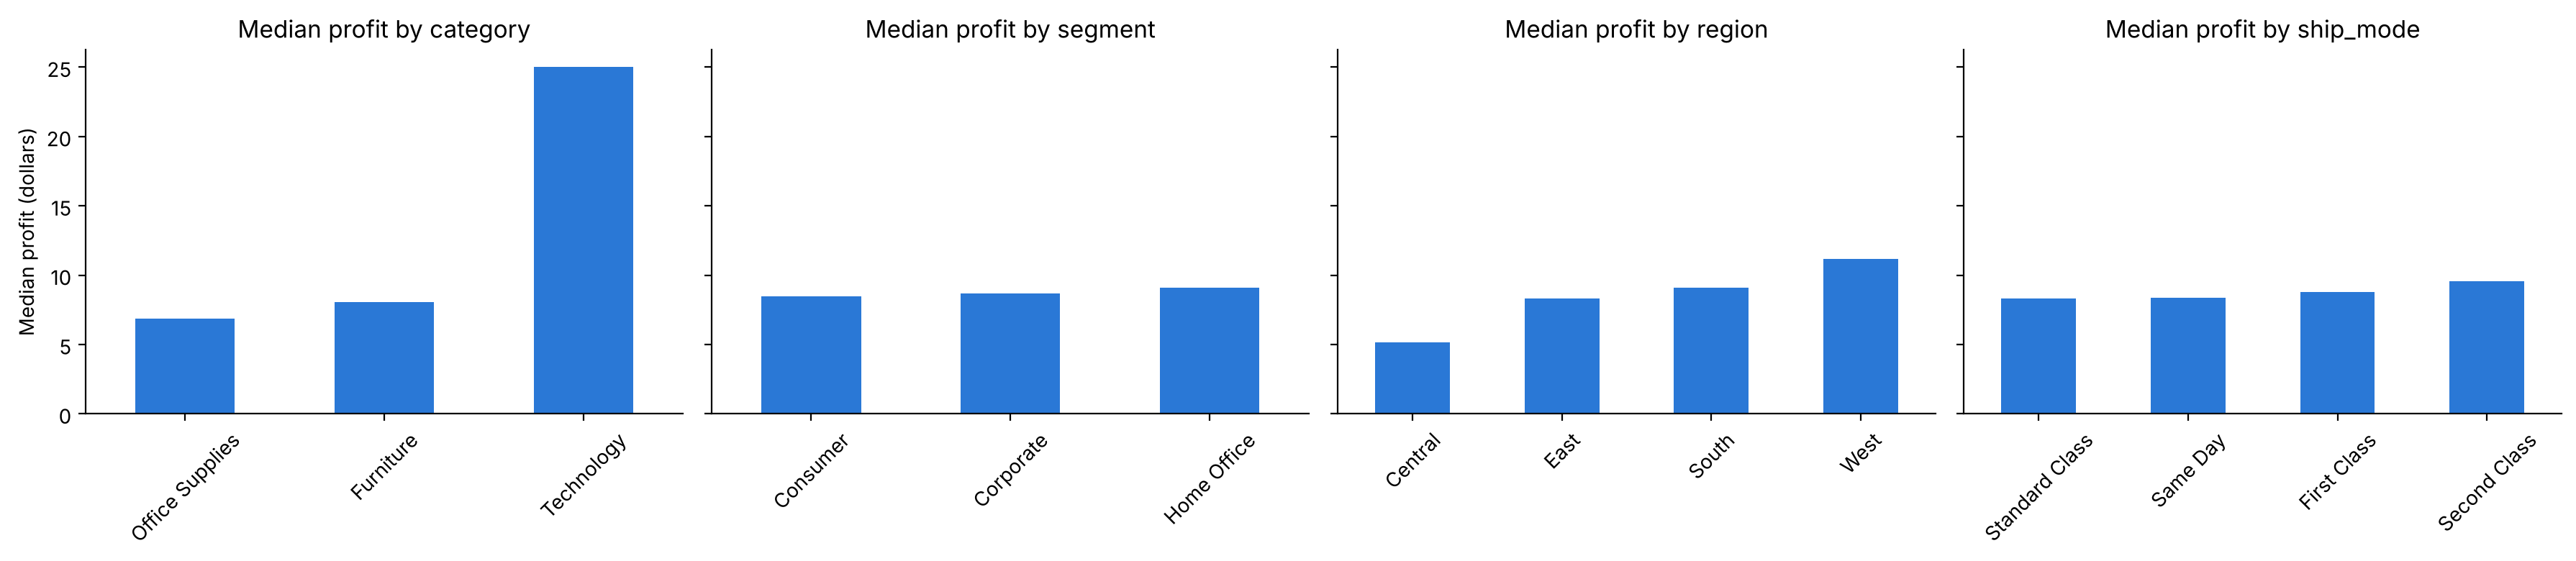

In [8]:
cat_cols = ["category", "segment", "region", "ship_mode"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, col in zip(axes, cat_cols):
    df.groupby(col)["profit"].median().sort_values().plot(kind="bar", ax=ax, color=BLUE)
    ax.set_title(f"Median profit by {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Median profit (dollars)")

plt.tight_layout()
plt.show()

I use the median instead of the mean here, because a few extreme orders would distort the mean. Technology has the highest median profit. Segment and ship mode show only small differences.

In [9]:
summary = df.groupby("category").agg(
    order_lines=("profit", "size"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    avg_discount=("discount", "mean"))
summary["margin"] = summary["profit"] / summary["sales"]
summary.round(3)

,order_lines,sales,profit,avg_discount,margin
category,,,,,
Furniture,2201,754747.761,19729.996,0.173,0.026
Office Supplies,6128,731893.314,126023.443,0.156,0.172
Technology,1865,839893.279,146543.376,0.131,0.174


All three categories have similar total sales, but **Furniture** earns almost nothing: its overall margin is below 3%, compared to about 17% for Office Supplies and Technology. Furniture also gets the highest average discount. The next sections check whether these two facts are connected.

## 5. Discount and profit

The dataset uses only a few fixed discount levels, so I can look at each level separately.

In [10]:
by_discount = df.groupby("discount").agg(
    order_lines=("profit", "size"),
    total_profit=("profit", "sum"),
    share_with_loss=("profit", lambda s: (s < 0).mean()),
    median_margin=("margin", "median"))
by_discount.round(3)

,order_lines,total_profit,share_with_loss,median_margin
discount,,,,
0.00,4925,326718.587,0.000,0.340
0.10,96,9099.970,0.042,0.167
0.15,52,1418.991,0.327,0.047
0.20,3706,91079.952,0.138,0.175
0.30,230,-10513.446,0.917,-0.086
0.32,27,-2391.138,1.000,-0.176
0.40,207,-23086.374,0.874,-0.233
0.45,11,-2493.111,1.000,-0.436
0.50,66,-20506.428,1.000,-0.600


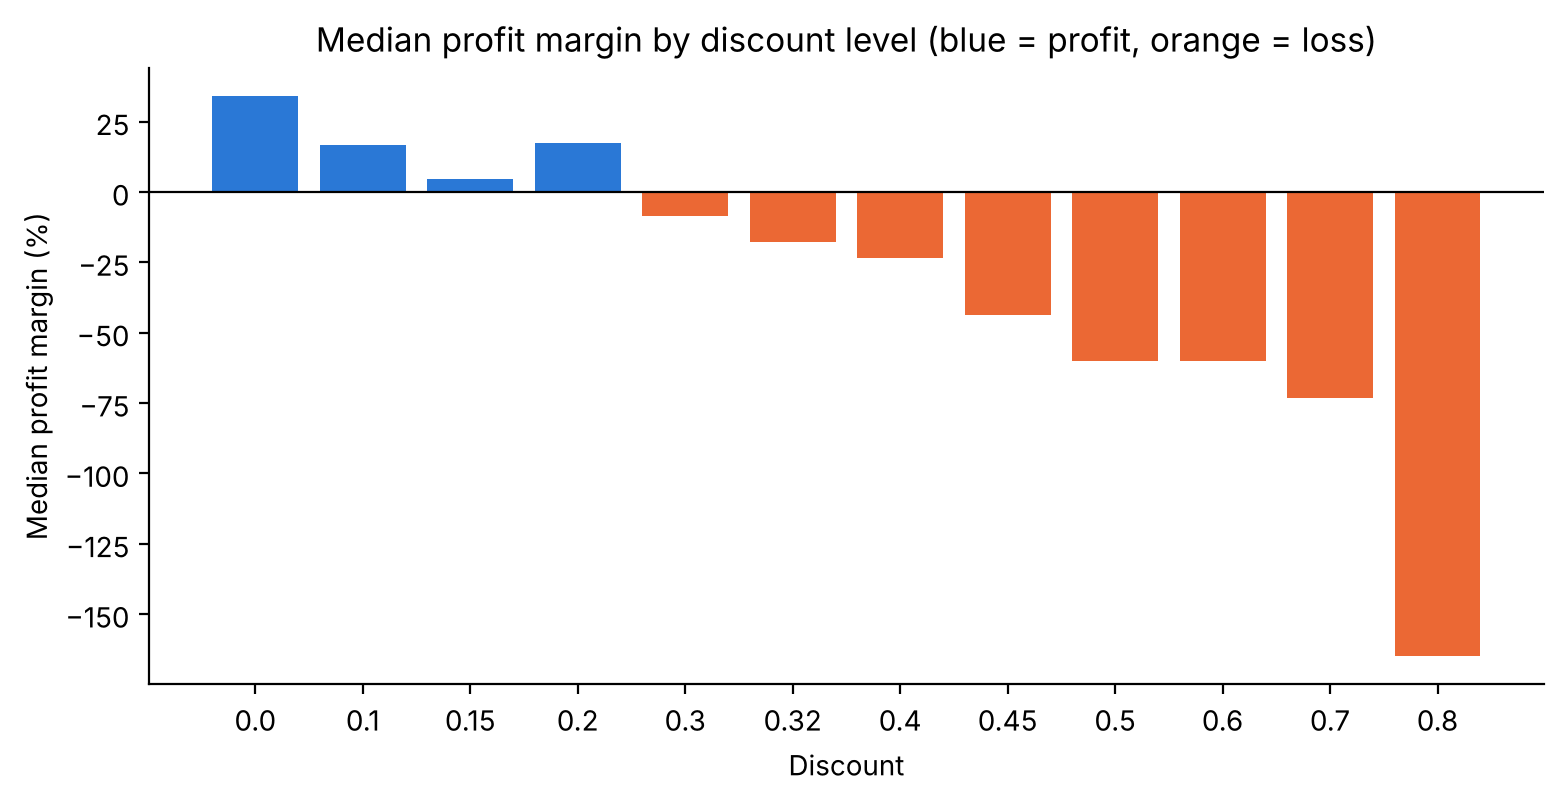

In [11]:
colors = [BLUE if m >= 0 else ORANGE for m in by_discount["median_margin"]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_discount.index.astype(str), by_discount["median_margin"] * 100, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Discount")
ax.set_ylabel("Median profit margin (%)")
ax.set_title("Median profit margin by discount level (blue = profit, orange = loss)")
plt.show()

In [12]:
high = df["discount"] > 0.2

print(f"Order lines with more than 20% discount: {high.sum()} ({high.mean():.1%} of all lines)")
print(f"Their total profit:        {df.loc[high, 'profit'].sum():>12,.0f} dollars")
print(f"Profit of all other lines: {df.loc[~high, 'profit'].sum():>12,.0f} dollars")
print(f"Total profit:              {df['profit'].sum():>12,.0f} dollars")

Order lines with more than 20% discount: 1415 (13.9% of all lines)
Their total profit:            -136,021 dollars
Profit of all other lines:      428,318 dollars
Total profit:                   292,297 dollars


This is the clearest result of the analysis:

- **Up to 20% discount**, most order lines are profitable: at 20% discount, the most common discount level, 86% of the lines still make a profit. (The 15% level is an exception with a third of the lines losing money, but it has only 52 lines, all of them furniture.)
- **From 30% discount on**, between 87% and 100% of the order lines lose money, and the median margin is negative at every level.
- The order lines with more than 20% discount are only about 14% of all lines, but together they lose about **136,000 dollars**. This cancels about a third of the profit made by all other order lines (about 428,000 dollars).

This is a correlation, not a proof of cause and effect: high discounts may also be given to products that are hard to sell anyway. The regression in section 7 checks whether the discount effect stays when product type and region are taken into account.

## 6. Product groups and regions

In [13]:
by_sub = df.groupby("sub_category").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    avg_discount=("discount", "mean"))
by_sub["margin"] = by_sub["profit"] / by_sub["sales"]

# typical margin when there is no discount: how profitable is the product itself?
by_sub["margin_without_discount"] = (
    df[df["discount"] == 0].groupby("sub_category")["margin"].median())

by_sub = by_sub.sort_values("profit")
by_sub.round(3)

,sales,profit,avg_discount,margin,margin_without_discount
sub_category,,,,,
Tables,208020.182,-17753.206,0.258,-0.085,0.210
Bookcases,115361.204,-3632.074,0.215,-0.031,0.220
Supplies,46725.498,-1171.394,0.076,-0.025,0.270
Fasteners,8532.240,2428.636,0.079,0.285,0.460
Machines,189925.031,3461.977,0.304,0.018,0.460
Labels,12695.042,5572.778,0.071,0.439,0.470
Art,27659.014,6653.196,0.075,0.241,0.290
Envelopes,16528.362,6988.025,0.080,0.423,0.470
Furnishings,95598.126,13891.743,0.138,0.145,0.340


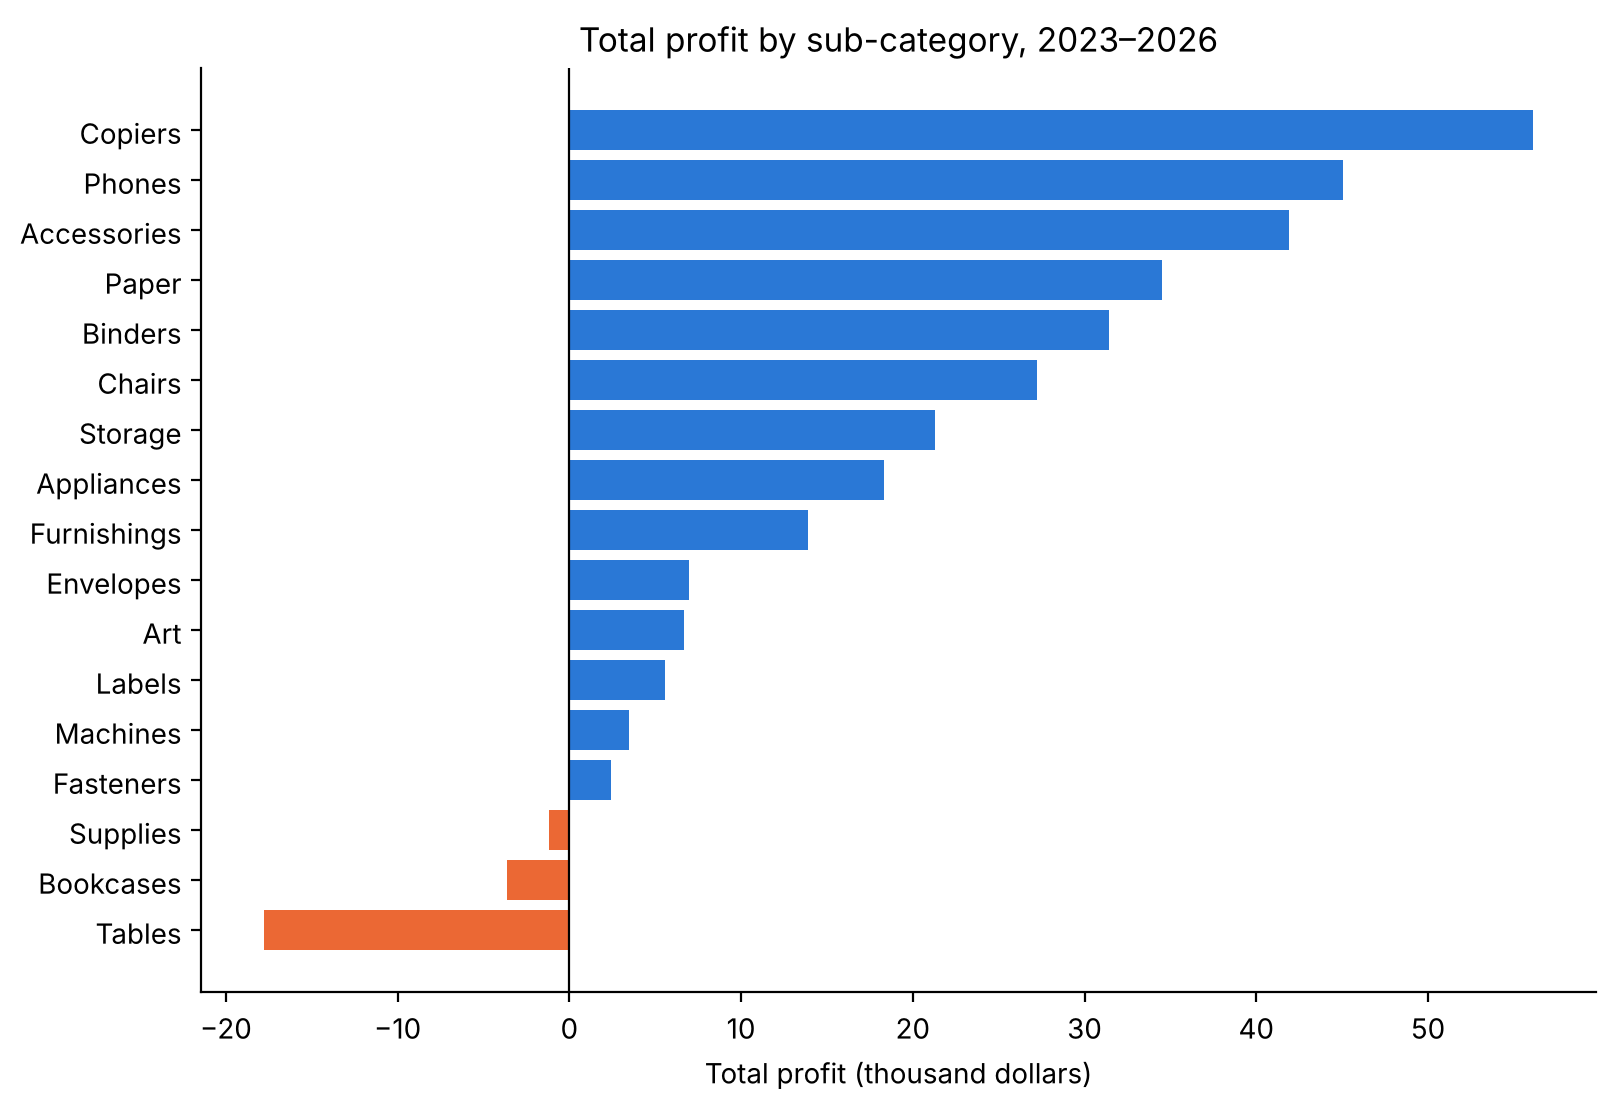

In [14]:
colors = [BLUE if p >= 0 else ORANGE for p in by_sub["profit"]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(by_sub.index, by_sub["profit"] / 1000, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Total profit (thousand dollars)")
ax.set_title("Total profit by sub-category, 2023–2026")
plt.show()

Three sub-categories lose money in total: **Tables**, **Bookcases** and **Supplies**.

- Without a discount, these products are still profitable (median margin of about 21% to 27%), but their margin is lower than for most other products.
- **Tables** and **Bookcases** also get high average discounts (26% and 22%), so their thin margin is used up by the discount.
- **Supplies** gets low discounts, so the reason is different: a few expensive electric letter openers were sold at 20% discount with large losses.
- Some products with high discounts stay profitable because their own margin is high. **Binders**, for example, have the highest average discount (37%), but a margin of about 47% without discount.

In [15]:
by_region = df.groupby("region").agg(
    profit=("profit", "sum"),
    sales=("sales", "sum"),
    share_high_discount=("discount", lambda s: (s > 0.2).mean()))
by_region["margin"] = by_region["profit"] / by_region["sales"]
by_region.sort_values("margin").round(3)

,profit,sales,share_high_discount,margin
region,,,,
Central,39865.307,503170.673,0.277,0.079
South,46749.430,391721.905,0.106,0.119
East,94883.260,691828.168,0.160,0.137
West,110798.817,739813.608,0.036,0.150


The **Central** region has the lowest margin (about 8%) and also by far the most order lines with more than 20% discount (28%, compared to 4% in the West). Whether the region itself matters or only its discount policy is a question for the regression model.

## 7. Regression models

I compare four linear regression models (OLS). To compare them fairly, I use **5-fold cross-validation**: the data is split into five parts, each model is trained on four parts and tested on the fifth, and this is repeated five times.

In my first version I used one train/test split. The R² was 0.18 on the training data but 0.41 on the test data, which only happened because a few extreme orders landed in the training set. Cross-validation shows how much the result depends on the split.

All models are evaluated on the same scale, **profit in dollars**, even if they are trained on another target:

| Model | Target | Features |
| --- | --- | --- |
| 1. Profit model | profit | sales, discount, category, region, segment |
| 2. Log-profit model | signed log of profit | same as model 1 |
| 3. Margin model | margin | discount (as a number), sub-category, region, segment |
| 4. Margin model with discount levels | margin | discount (each level as a category), sub-category, region, segment |

For models 3 and 4, the predicted profit is the predicted margin multiplied by the sales of the order line.

In [16]:
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error

# signed log: keeps the sign and compresses the scale
# log1p(|x|) = log(1 + |x|), so it is also defined for 0
df["profit_log"] = np.sign(df["profit"]) * np.log1p(np.abs(df["profit"]))

models = {
    "1. Profit": ("profit ~ sales + discount + C(category) + C(region) + C(segment)",
                  lambda pred, data: pred),
    "2. Log-profit": ("profit_log ~ sales + discount + C(category) + C(region) + C(segment)",
                      lambda pred, data: np.sign(pred) * np.expm1(np.abs(pred))),
    "3. Margin": ("margin ~ discount + C(sub_category) + C(region) + C(segment)",
                  lambda pred, data: pred * data["sales"]),
    "4. Margin, discount levels": ("margin ~ C(discount) + C(sub_category) + C(region) + C(segment)",
                                   lambda pred, data: pred * data["sales"]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, (formula, to_dollars) in models.items():
    target = formula.split(" ~ ")[0]
    r2_target, r2_profit, mae_profit = [], [], []

    for train_idx, test_idx in cv.split(df):
        train, test = df.iloc[train_idx], df.iloc[test_idx]
        pred = smf.ols(formula, data=train).fit().predict(test)

        r2_target.append(r2_score(test[target], pred))
        pred_profit = to_dollars(pred, test)
        r2_profit.append(r2_score(test["profit"], pred_profit))
        mae_profit.append(mean_absolute_error(test["profit"], pred_profit))

    rows.append({"Model": name,
                 "R² on own target": np.mean(r2_target),
                 "R² on profit (mean)": np.mean(r2_profit),
                 "R² on profit (worst fold)": np.min(r2_profit),
                 "MAE on profit (dollars)": np.mean(mae_profit)})

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,R² on own target,R² on profit (mean),R² on profit (worst fold),MAE on profit (dollars)
Model,,,,
1. Profit,0.142,0.142,-0.486,58.278
2. Log-profit,0.504,-928200.572,-4610187.100,2246.892
3. Margin,0.814,0.631,-0.022,31.251
"4. Margin, discount levels",0.940,0.843,0.503,17.823


How to read the table:

- **Model 1** (my original model) explains only a small part of the profit and is very unstable: in one fold the R² is negative, so the model is worse than simply predicting the average.
- **Model 2** (signed log) looked much better in my first version, with a stable R² of about 0.50. But that R² is measured on the log scale. When the predictions are converted back to dollars, small errors on the log scale become huge errors in dollars, and the model becomes unusable for predicting profit. The transformation made the numbers look better, but it did not solve the problem.
- **Model 3** changes the question: instead of the profit in dollars, it predicts the margin. This removes most of the effect of order size, and the model explains about 81% of the variation in margins.
- **Model 4** treats each discount level as its own category. The section 5 chart showed that the margin does not fall in a straight line with the discount: the step from 70% to 80% costs much more than the step from 0% to 10%. With this change the model explains about 94% of the variation in margins and is clearly the best model in dollars too.

The worst fold in dollars is still weaker than the average, because a few very large orders dominate the error. This is the limit of a model with fixed margins.

**A note on the data:** an R² of 0.94 is unusually high for real business data. Superstore is a fictional dataset, and its profit values were probably generated from rules based on product and discount. With real data I would expect a lower value.

## 8. The final model

I fit model 4 on all data to interpret its coefficients. The model is evaluated with cross-validation above; here I only look at what it says.

The reference levels (the ones without their own coefficient) are: no discount, sub-category `Accessories`, region `Central` and segment `Consumer`. Each coefficient shows how much the margin changes compared to that reference, with all other features kept the same. For example, -0.10 means 10 percentage points less margin.

In [17]:
final = smf.ols("margin ~ C(discount) + C(sub_category) + C(region) + C(segment)",
                data=df).fit()

print(f"R²: {final.rsquared:.3f}   Adjusted R²: {final.rsquared_adj:.3f}   Observations: {int(final.nobs)}")
print(f"Intercept (margin of the reference levels): {final.params['Intercept']:.3f}")


def coef_table(prefix):
    # coefficients and p-values for one group of dummy variables
    rows = [name for name in final.params.index if name.startswith(prefix)]
    table = pd.DataFrame({"coefficient": final.params[rows],
                          "p_value": final.pvalues[rows]})
    table.index = [name.split("[T.")[1].rstrip("]") for name in rows]
    return table.round(3)


coef_table("C(discount)")

R²: 0.941   Adjusted R²: 0.941   Observations: 10194
Intercept (margin of the reference levels): 0.284


,coefficient,p_value
0.1,-0.060,0.0
0.15,-0.080,0.0
0.2,-0.173,0.0
0.3,-0.311,0.0
0.32,-0.296,0.0
0.4,-0.476,0.0
0.45,-0.622,0.0
0.5,-0.741,0.0
0.6,-1.005,0.0
0.7,-1.315,0.0


In [18]:
coef_table("C(sub_category)").sort_values("coefficient")

,coefficient,p_value
Bookcases,-0.165,0.000
Storage,-0.130,0.000
Tables,-0.122,0.000
Supplies,-0.106,0.000
Chairs,-0.083,0.000
Appliances,-0.068,0.000
Phones,-0.016,0.004
Art,0.031,0.000
Furnishings,0.044,0.000
Fasteners,0.088,0.000


In [19]:
pd.concat([coef_table("C(region)"), coef_table("C(segment)")])

,coefficient,p_value
East,0.005,0.182
South,0.003,0.415
West,-0.006,0.058
Corporate,0.006,0.025
Home Office,0.003,0.294


**Discount** has by far the largest effect. Compared to no discount, a 20% discount lowers the margin by about 17 percentage points and a 30% discount by about 31 points. Since a product without discount has a margin of about 28% (the intercept), the break-even point lies between 20% and 30% discount for a typical product.

**Sub-category:** with the same discount, Bookcases, Storage, Tables and Supplies have a 10 to 17 points lower margin than Accessories, while Binders, Envelopes, Paper and Labels have a 20 to 26 points higher margin. So Tables and Bookcases lose money for two reasons together: a thin margin *and* high discounts.

**Region and segment** have almost no effect (all below 1 percentage point) once the discount is in the model. The low margin in the Central region from section 6 is therefore explained by its higher discounts, not by the region itself.

## 9. Model diagnostics

OLS assumes that the residuals (actual minus predicted margin) are centred around zero with a similar spread everywhere. I check this with three plots.

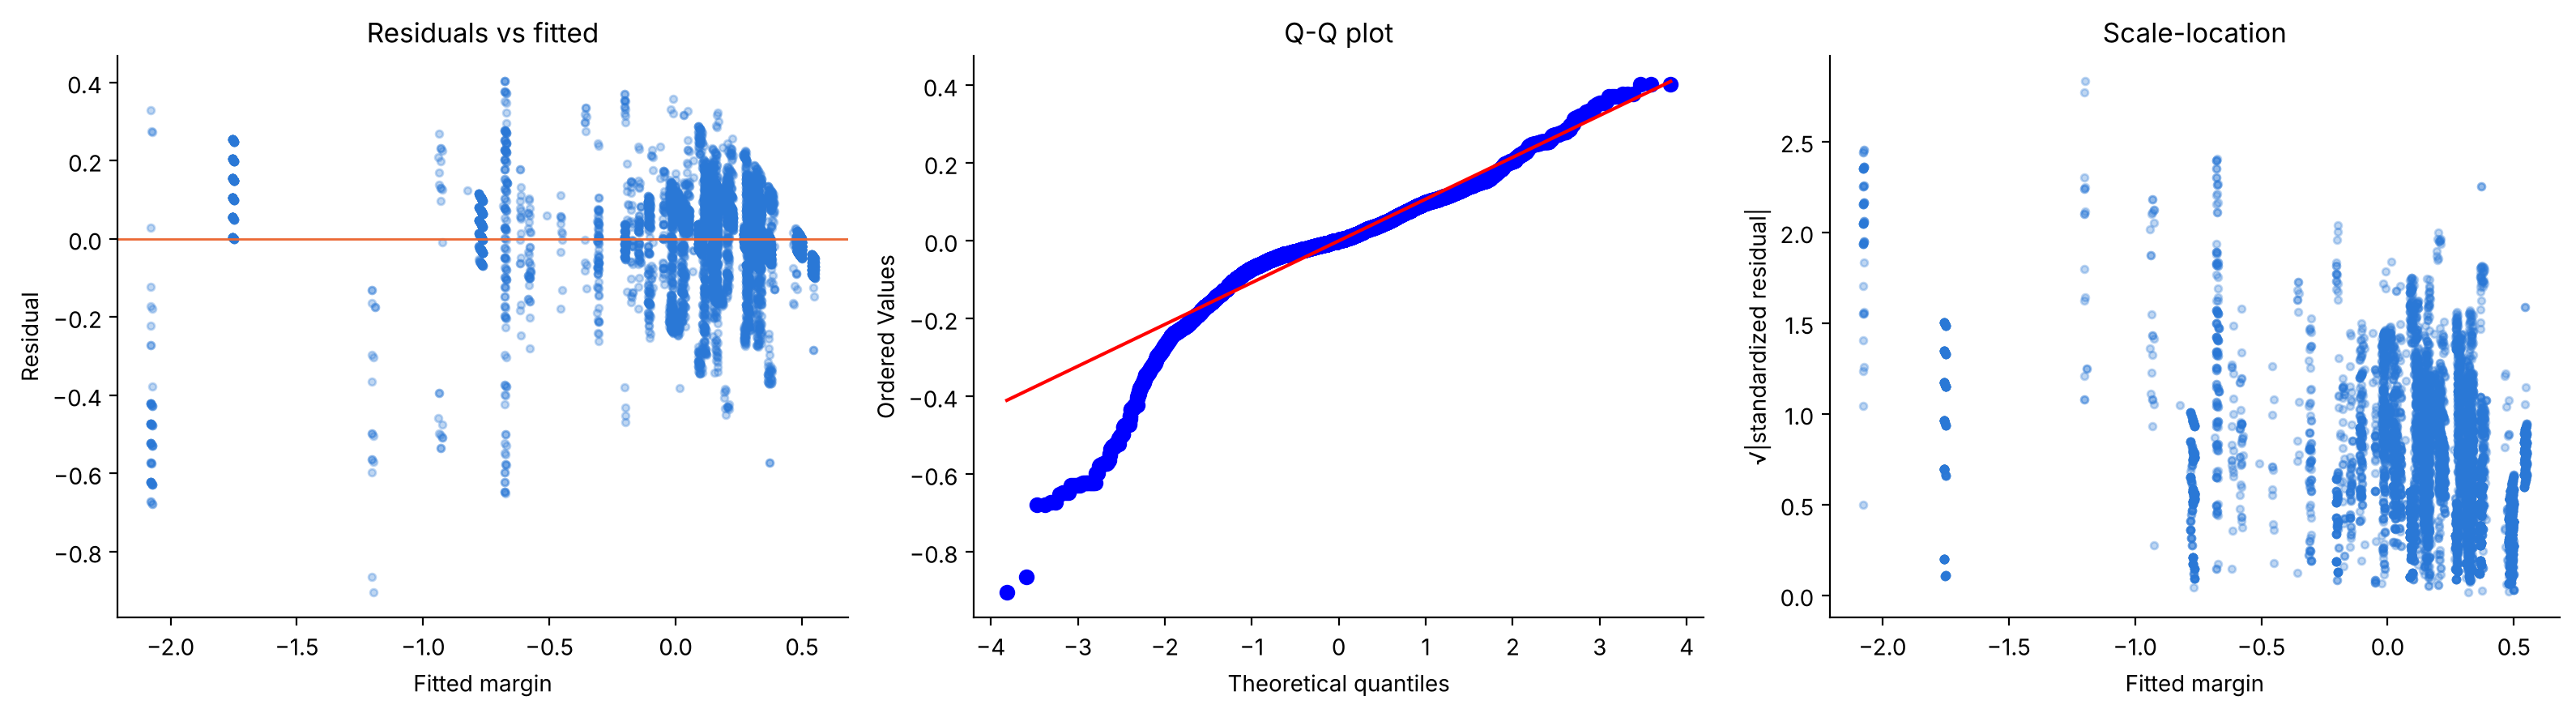

Skew:     -1.32
Kurtosis: 5.96


In [20]:
residuals = final.resid
fitted = final.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. residuals vs fitted values
axes[0].scatter(fitted, residuals, alpha=0.3, s=10, color=BLUE)
axes[0].axhline(0, color=ORANGE, linewidth=1)
axes[0].set_xlabel("Fitted margin")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted")

# 2. Q-Q plot: are the residuals normally distributed?
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot")

# 3. scale-location: is the spread the same everywhere?
std_resid = residuals / residuals.std()
axes[2].scatter(fitted, np.sqrt(np.abs(std_resid)), alpha=0.3, s=10, color=BLUE)
axes[2].set_xlabel("Fitted margin")
axes[2].set_ylabel("√|standardized residual|")
axes[2].set_title("Scale-location")

plt.tight_layout()
plt.show()

print("Skew:    ", round(stats.skew(residuals), 2))
print("Kurtosis:", round(stats.kurtosis(residuals), 2))

In [21]:
# Cook's distance: which order lines have the largest influence on the model?
cooks_d = final.get_influence().cooks_distance[0]

threshold = 4 / len(df)
print(f"Influential points (Cook's distance > 4/n): {(cooks_d > threshold).sum()} of {len(df)}")

top10 = np.argsort(cooks_d)[-10:]
df.iloc[top10][["category", "sub_category", "region", "sales", "discount", "profit", "margin"]].round(3)

Influential points (Cook's distance > 4/n): 563 of 10194


,category,sub_category,region,sales,discount,profit,margin
8349,Furniture,Furnishings,Central,16.784,0.60,-22.239,-1.325
8955,Furniture,Bookcases,West,217.764,0.70,-384.716,-1.767
39,Furniture,Bookcases,West,181.470,0.70,-320.597,-1.767
4037,Technology,Machines,East,1799.994,0.70,-2639.991,-1.467
6398,Technology,Machines,East,4499.985,0.70,-6599.978,-1.467
8776,Furniture,Bookcases,West,72.588,0.70,-128.239,-1.767
985,Furniture,Tables,South,174.058,0.45,-110.764,-0.636
10043,Furniture,Bookcases,West,102.018,0.70,-183.632,-1.800
3975,Furniture,Bookcases,West,69.576,0.70,-143.790,-2.067
5928,Furniture,Bookcases,West,90.882,0.70,-190.852,-2.100


- The residuals are centred around zero, but they are not normally distributed: in the Q-Q plot the points leave the line at the lower end, so for some order lines the real margin is much lower than predicted.
- The spread is also not the same everywhere: it is larger on the left side of the plots, where the fitted margins are strongly negative (the deep discounts of 60% to 80%).
- So the p-values of the model should be read with some caution. With more than 10,000 rows and very large effects, the main conclusions about discount and sub-category are not affected.
- The rule of thumb 4/n flags several hundred points as influential, which is normal for a dataset of this size. The most influential lines are listed above; they are real orders, not data errors, so I keep them.

## 10. Conclusions

1. **Discounts above 20% are the main reason for losses.** Up to 20% discount most order lines are profitable; from 30% on almost all of them lose money. The lines with more than 20% discount (about 14% of all lines) lose about 136,000 dollars together.
2. **Product type sets how much discount is possible.** Products with a high margin (Binders, Paper, Copiers) can absorb a discount; Tables and Bookcases cannot, because their margin is thin to begin with.
3. **Region and customer segment don't matter once discount is known.** The weak result of the Central region comes from its discount policy.
4. **For the model, the choice of target mattered more than the choice of method.** Predicting the margin instead of the profit in dollars, and treating discount levels as categories, raised the cross-validated R² from about 0.14 to about 0.84 (in dollars).

**Recommendations** (based on this fictional data):

- Set a maximum discount of 20% by default, and require approval for higher discounts.
- Set the discount limit per product group: lower for Tables, Bookcases and Supplies, higher for products with a large margin.
- Review the discount practice in the Central region first, since it gives the most high discounts.

**Limitations**

- The data is fictional, so the very clear patterns are likely cleaner than in real data.
- The analysis shows associations. It cannot show whether customers would still buy without the discount; this would need an experiment (for example an A/B test of discount levels).
- Large single orders still cause large errors in dollars.